
To begin let's start by defining a couple of key concepts and looking at examples of them.

### Definition: Target
We define the Target as the output feature in our model. The Target feature is referred to as the *Dependent Variable* in statistics derived literature. When modeling we typically denote the target feature with the symbol $Y$. When programming we may sometimes instantiate the variable with a more descriptive name. In Linear Regression the Target Variable is an instance of a Real Number, not an Integer, and definately not a binary variable or class.

### Example
In a typical linear regression example we might be interested in modeling the relationship between height and age. In this case our Target feature or dependent variable is *height*.

Assuming measurements in meters we can instantiate a vector of height measurements in numpy using the 'array' function where the resultant array is equivalent to a vector. Remember that the numpy array is actually initialized from a native python array.

In [12]:
import numpy as np
Y = np.array([60,90,100.5,130,128,140,160,140,165,162,155])
print("Our height vector is ", Y)

Our height vector is  [ 60.   90.  100.5 130.  128.  140.  160.  140.  165.  162.  155. ]


As an aside, familiarise yourself with Numpy if you are not already familiar with it. Numpy is a library for manipulating vectors and is used extensively in many different scientified computing applications in Python.

### Definition: Predictor Features
The Predictor Features are the input features to our model and are referred to as *Independent Variables* in the statistics literature. A nice way of remembering this is that we ideally want *independent features*. The predictor features are usually denoted with the symbol $X$. A single $X$ is used in the case where there is only one predictor feature (usually only in toy examples) while $X$ is indexed ($X_{1}$) where there is more than one predictor feature.

In our height modeling example we might start out with the case of a single Predictor Feature *age*:

In [13]:
X = np.array([1,3,4,7,10,11,14,13.5,16,18,22])
print("Our age vector is ", X)

Our age vector is  [ 1.   3.   4.   7.  10.  11.  14.  13.5 16.  18.  22. ]


In most cases that we start with, the Independent Variable / Features are generally Real Valued but the conditions are not as strict as with the Dependent Variable. We can have binary values as the Independent Variable but for most of our cases we will stick with real valued inputs.

### Note - Terminology
By convention we usually refer to the Target feature as the **Target** and the Predictor Features as simply the **Features**.

### Example: Height as a Function of Age
We can visualize our Height and Age data as follows:


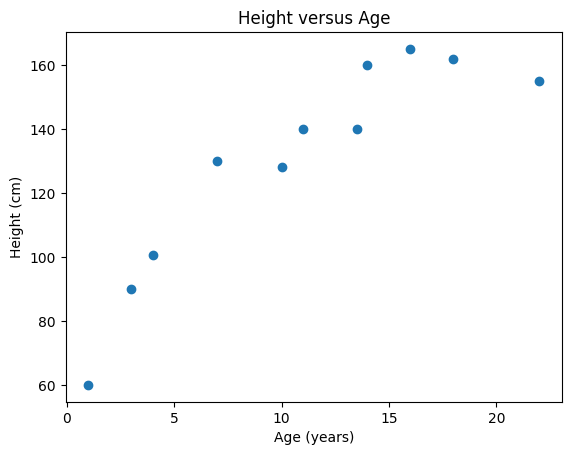

In [14]:
%matplotlib inline

import matplotlib.pyplot as plt

plt.plot(X,Y, "o")
plt.title('Height versus Age')
plt.xlabel('Age (years)')
plt.ylabel('Height (cm)')
plt.show()

Examining our data we can clearly see a relationship between Age and Height but how do we model the relationship between the two variables? We could start with correlation:

In [15]:
from scipy.stats import pearsonr
r,p = pearsonr(X,Y)
print('r value is ',r)
print('p value is',p)

r value is  0.9028496585155188
p value is 0.00014105270724641005


Correlation confirm that there is a strong positive relationship between the two variables, but this is useless if we want to be able to predict a value for our Target (*Height*) based on a new value for our Feature (*Age*). For example lets say that we want to know the most likely value for *Height* based on an *Age* of 9. We can do this intuitively by looking at our plot and estimating what value on the Y axis corresponds to 9 on the X axis.

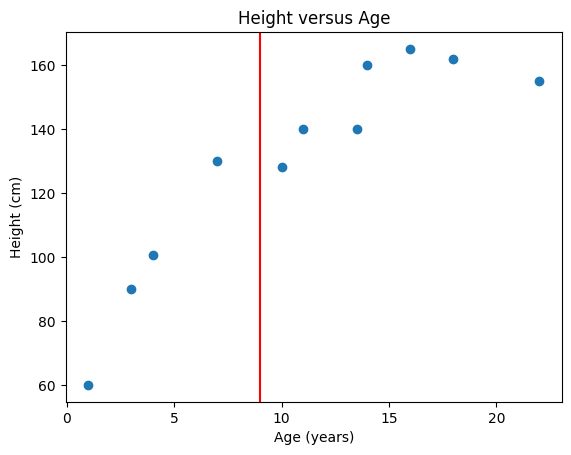

In [16]:
plt.axvline(9, color='red')
plt.plot(X,Y, "o")
plt.title('Height versus Age')
plt.xlabel('Age (years)')
plt.ylabel('Height (cm)')
plt.show()

### Definition: Linear Regression
Linear Regression is an approach to modeling the relationship between a Target and Features with a parameterised function.

The most basic function we can fit to our example is a straight line of the form:

\begin{equation}
 Y = mX + c
\end{equation}

where $m$ defines the slope of the line and $c$ defines the line's offset from the origin.

For this toy example we can look at the data and guess that a reasonable fit to the data might be

\begin{equation}
 Y = 4X + 80
\end{equation}

Generally though for linear regression we rewrite the equation above such that the intercept is placed before the slope term as follows:

\begin{equation}
 Y = 80 + 4X
\end{equation}

We can plot a graph of this line / function against our data as follows:

[ 80  84  88  92  96 100 104 108 112 116 120 124 128 132 136 140 144 148
 152 156 160 164 168 172 176]


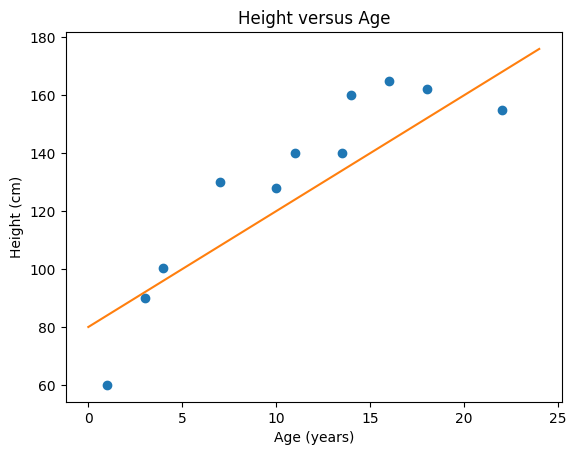

In [17]:
plt.plot(X,Y, "o")
plt.title('Height versus Age')
plt.xlabel('Age (years)')
plt.ylabel('Height (cm)')
x2 = np.array([i for i in range(25)])
y2 = 80 + 4*x2
print(y2)
plt.plot(x2,y2)
plt.show()

Alternatively we might think that the linear function $Y= 60 + 6X$ might give a better fit.

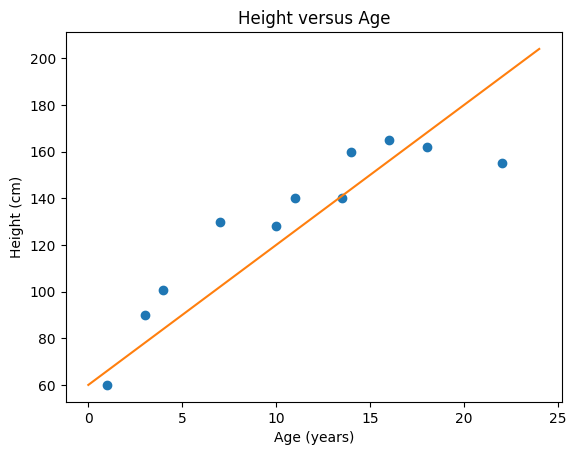

In [18]:
plt.plot(X,Y, "o")
plt.title('Height versus Age')
plt.xlabel('Age (years)')
plt.ylabel('Height (cm)')
x2 = np.array([i for i in range(25)])
y2 = 60 + 6*x2
plt.plot(x2,y2)
plt.show()

We might even think that a polynomial such as
\begin{equation}
Y = 50 + 15X - 0.68 X^{2} + 0.011 X^{3}
\end{equation}

would provide a better fit again.

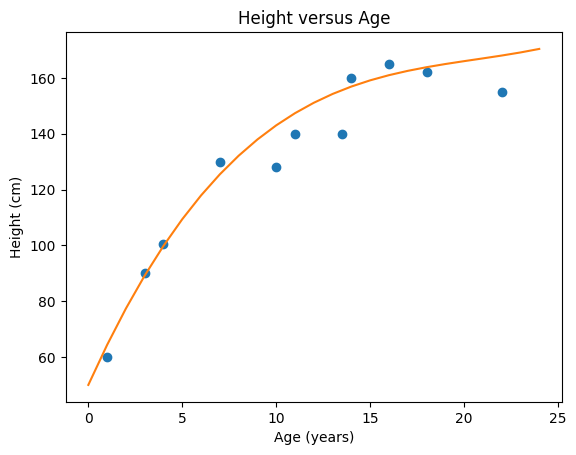

In [19]:
plt.plot(X,Y, "o")
plt.title('Height versus Age')
plt.xlabel('Age (years)')
plt.ylabel('Height (cm)')
x2 = np.array([i for i in range(25)])
y2 = 50 + 15*x2 - 0.68*(x2**2)  + 0.011*(x2**3)
plt.plot(x2,y2)
plt.show()

## Classification

The examples above were 'regression' examples as our target variable was real valued. In many cases our target variable will be a class. the basic case here is when we have to select between two targets as the class. Let's look at an example:

In [20]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt

# Target Variable - diagnosed onset of Type II diabetes
Y = np.array([0,0,0,0,1,1,1,1])
# Input Feature - Average daily consumption of added sugars in grammes
X = np.array([5,10,15,20,30,40,45,60])


In the data above we define a very simple set of cases. Our input variable is average daily sugar consumption in grammes (made up values) and our target variable is a class variable indicating if the person has a propensity to diabetes or not. Again, this data is all synthetic, so don't over-read into it. Our target class is represented as 1 or 0. This allows the maths to work. Whenever we have cases like A vs B, the actual Deep Learning (or machine learning) will usually map to numbers such as 1 vs 0.

We can visualize this data.

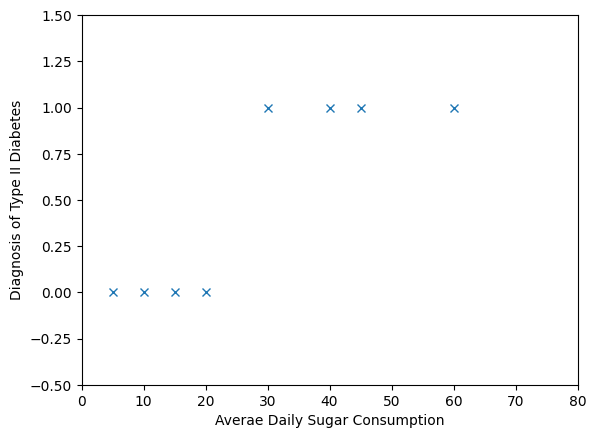

In [21]:

plt.plot(X,Y, "x")
plt.xlabel('Averae Daily Sugar Consumption')
plt.ylabel('Diagnosis of Type II Diabetes')
plt.ylim([-0.5,1.5])
plt.xlim([0,80])
plt.show()

As can be seen there is a clear relationship between the amount of additional sugar consumed daily and the onset of diabetes (it should be noted that this is idealised data and not taken from a specific study). The question is how do we best model this data.

A function which models this data should be as close as possible to the data points as possible. We can naively try to map simple regression functions such as below:

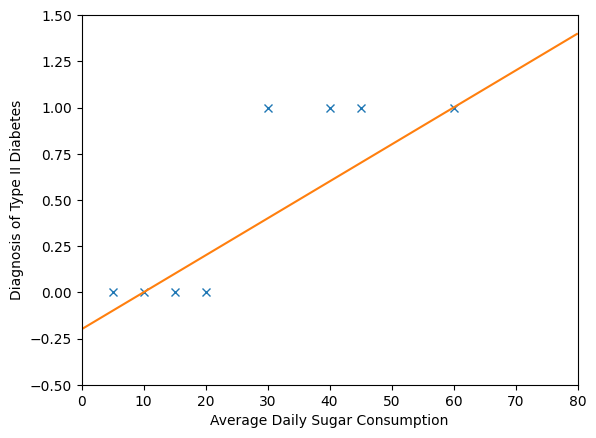

In [22]:
plt.plot(X,Y, "x")
plt.xlabel('Average Daily Sugar Consumption')
plt.ylabel('Diagnosis of Type II Diabetes')

x1 = np.arange(0,80,0.1)

plt.plot(x1,-0.2+(x1*0.02))

plt.ylim([-0.5,1.5])
plt.xlim([0,80])
plt.show()

The function we tried above (y = -0.2 + (x*.0.2)) is ok, but clearly not a great fit. You can pley around with different polynomials, and eventually they would given an ok fit if we introduce enough manipulations of X, but generally these would only work in a certain range.

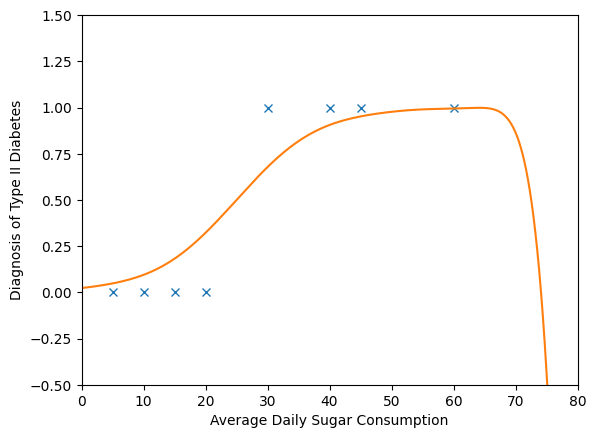

In [29]:
plt.plot(X,Y, "x")
plt.xlabel('Average Daily Sugar Consumption')
plt.ylabel('Diagnosis of Type II Diabetes')

x1 = np.arange(0,80,0.1)

def polynomial_approximation(x):
    x = x - 25
    x = x * 0.15
    return (
        0.5
        + 0.2468 * x
        - 0.01769 * x**3
        + 0.001085 * x**5
        - 0.000040960 * x**7
        + 0.0000008215 * x**9
        - 0.00000000664712 * x**11
    )

plt.plot(x1,polynomial_approximation(x1))

plt.ylim([-0.5,1.5])
plt.xlim([0,80])
plt.show()

There is a better type of function we can fit to the data -- it is called the logistic function and we will return to it next week.

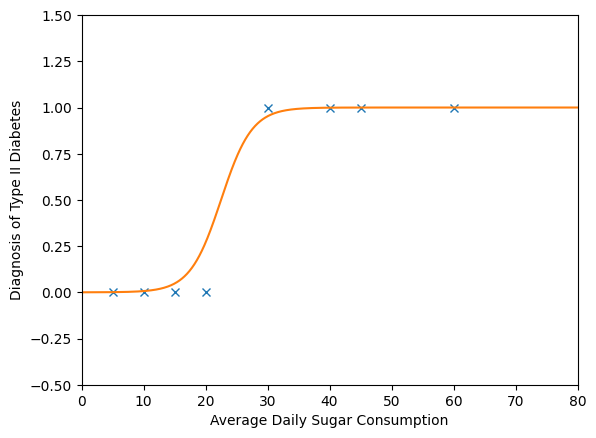

In [44]:
plt.plot(X,Y, "x")
plt.xlabel('Average Daily Sugar Consumption')
plt.ylabel('Diagnosis of Type II Diabetes')

x1 = np.arange(0,80,0.1)
x0 = np.array([1]*len(x1))
x = np.vstack((x0,x1))
z1 = np.matmul(np.array([-9,0.4]),x)

plt.plot(x1,1/(1 + np.exp(-z1)))
plt.ylim([-0.5,1.5])
plt.xlim([0,80])
plt.show()

Again, we can try to fit a handcrafted function to try to model this data:

# Measuring Error

Returning to the case of straightforward regression, we can see that some of our examples work better than others. In Deep Learning (and machine learning in general) the system will try to come up with the set of parameters that best fits the data. The mechanism to do this varies a lot from classical machine learning to deep learning, but in nearly all cases the mechanism used is dependent on some sort of metric of 'error', i.e., how wrong the current solution is.

In order to get our heads around how this works, first let's assume the existance of this function f which maps from X to Y. The specifics of how it works is up to the Neural Network, but we know it takes an input and produces an output. Below let's take a really simple example of a function that just scales the input and adds an offset.

\begin{equation}
f(X) = 1 + (x*0.1)
\end{equation}

In the (textbook) literature this is referred to as our **hypothesis function** as it is the thing that we are trying to test out or evaluate. The hypothesis function is also often referred to as simply **the function** or **model**. In the notes below we will refer to it simply as our model.  

The values of 1 and 0.1 are the parameters of our function. These are the things that the neural network has to figure out. In practice it will figure out way more parameters than just these -- think millions and billions of parameters. Formally these parameters are often referred to as **$\theta$ . In the examples above the parameters were selected by manually playing with the parameters until a reasonable fit was found. In Deep Learning we automate the selection of these parameters by minimizing a Cost Function.

## Cost Functions

**Definition** The cost function, $J$, is a function which gives us a numeric estimate of the error between the predictions of our model and the test data values.

**Formal Definition**

\begin{equation}
J(\theta_{0},\theta_{1}) = \frac{1}{2m}     \sum_{i=0}^{m} ( h_{\theta}(x^{(i)}) - y^{(i)})^{2}
\end{equation}

where
 * $\theta_{0}$ and $\theta_{1}$ are the parameters of our model
 * $m$ is the number of training examples
 * $y^{i}$ is the ith target value
 * $x^{i}$ is the ith feature vector, and
 * $h_{\theta}$ is our model (hypothesis function of $x$) that we wish to evaluate.

 **Less Formal Definition**

\begin{equation}
Cost = \frac{1}{m}  \sum_{i=0}^{m} ( f(x^{(i)}) - y^{(i)})^{2}
\end{equation}

where f(x) is our prediction and y is our target (training) value.

**Intuition**

The intuition for the cost function is that it is measuring the difference between the ground truth values for our data and the predictions of our model. However rather than us adding up the differences we add up the square of the differences. This has two positive effects. First positive and negative difference values for different training examples won't cancel each other out. Secondly our model will heavily penalize cases where the predicted value is far away from the truth, but will only lightly penalize cases where there is a small difference between truth and prediction. This allows the search for the best fit to focus broadly on fixing up the big problems.

We divide by $m$ (the number of training examples) to provide balance over the amount of training data.

This cost function is often referred to as the **Sum of Squared Error** cost function.

We can map out the costs for different sets of parameters and they will generally form nice looking surfaces for simple problems, but will quickly become very noisy for more complex problems. For problems with multiple inputs, the cost surface quickly becomes a multidimensional surface that we can't visualize so easily. See the lecture slides.

# Neural Network Representation

In the examples above we hand crafted funcitons of our data and talked a little bit about how we might measure if they are wrong. But handcrafting can only get us so far.

## Motivation

The problem with this approach is that it does not scale. Traditional methods for directly learning models from data (linear regression and logistic regression) will need representations of the data that capture some of its complexities. In order to achieve complex non-linear decision boundaries in a classification problem we might have to add many additional features. If we are introducing quadratic or other higher order polynomial variants this can lead to an exponential number of features.

Neural Networks allow us to build non-linear models without having to manual encode all of these additional higher order features from our base features. The network itself looks at building these higher-order features as part of its own training process. The advantage of this method is that we don't have to guess what higher order features are useful - the neural network will only create higher order features that are shown to have a beneficial effect.

The disadvantage to this neural network approach is computational cost. Neural Networks are orders of magnitude more expensive to train than a logistic regression classifier - even if that classifier has had many extra manually created features added through data expansion. From the mid 1990s to the early 2010s this high computational cost meant that neural networks were not practical problem solvers. However, faster CPUs and speed-ups made possible by GPUs have allowed Neural Networks to finally realize their promise.

## Logistic Units
Neural Networks are architectures of simple processing units called neurons which are inspired by neurons in the brain but which are really just simple computational units which calculate a function of their input. Taken individually these neurons cannot achieve much, but when integrated into a complex architecture and trained with a powerful learning algorithm, they can build complex non-linear models over our data.

In practice many different types of neurons can be used to implement a neural network. Here we will begin by focusing on one of the most important of the these, the logistic unit or logistic neuron.

A logistic unit is based on the logistic function introduced above. In simple terms, the logistic unit makes a binary classification decision based on the application of the logistic function to the negative scalar product of an input vector times some parameters. This is formalized in the function below:

\begin{equation}
h_{\theta}(x) = \frac{1}{1 + x^{-\theta x}}
\end{equation}

or

\begin{equation}
h_{\theta}(x) = \frac{1}{1 + e^{-z}}
\end{equation}

where z, the logit, is defined as:

\begin{equation}
z = \theta x
\end{equation}

In the above, $\theta$ are our model parameters, $x$ is our input data vector, and $h$ is the output of our function which is commonly referred to as the hypothesis. $z$ is the linear product of our parameters and input values, which as we have mentioned is often referred to as the **logit**.

We interpret the logistic function as follows:

\begin{equation}
h_{\theta}(x) = P(Y=1 \;|\; x_{i},\theta)
\end{equation}

meaning that we must apply a threshold to $h$ to get our classification decision.

As mentioned we can have many different types of neurons. The most significant difference between neuron types is the output or **activation function**. In the above the activation function is the logistic function, but a linear activation function can for example be used to produce a continuous real valued output from a neuron.

For example we can define and apply a simple linear classifier over two input variables. In the example below our target $Y$ indicates whether a part for a truck was found to be faulty following a vehicle inspection. Feature $x1$ indicates the number of years since the part was replaced and $x2$ indicates the distance the truck has traveled since the last inspection in kilometers.  

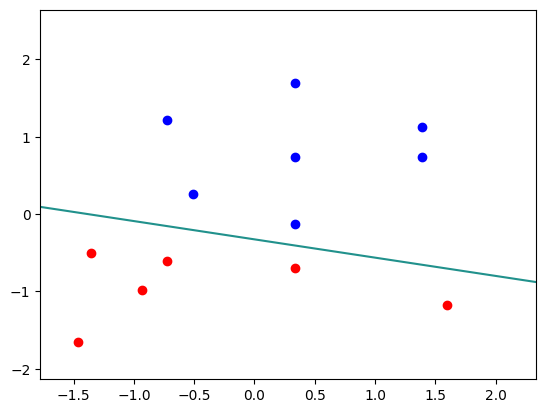

In [47]:
def logistic(theta,X):
    z = np.matmul(theta,X)
    return 1 / (1 + np.exp(-z))

def standardize(x):
    col_means = np.mean(x,axis=0)
    col_std = np.std(x,axis=0)
    return (x - col_means) / col_std , col_means, col_std

# Define the target values
Y =  [0,0,0,0,0,1,0,1,1,1,1,1,1]

# Define the 2 input features in a instance wise fashion
X = np.array([[0.3,50000],
              [3.2,100000],
              [0.4,170000],
              [0.8,120000],
              [2,150000],
              [1.2,250000],
              [1.0,160000],
              [2,210000],
              [2,300000],
              [2,400000],
              [3,300000],
              [3,340000],
              [1,350000]
             ])

# standardize our input data
X, means, stds = standardize(X)

# Define the function parameters - these were figured out using gradient descent (not shown here)
theta = [3.6,2.6,11]
#theta = [1.54092103, 10.25393618, 2.8042716 ]

# initialize values for features x1 and x2
x1_range = np.arange(0,4,0.1)
x2_range = np.arange(0.0,500000,1000.0)

x1s, x2s = np.meshgrid(x1_range, x2_range) # remember - plt.surface likes this meshgrid output
mesh_rows, mesh_cols = x1s.shape

# construct 1D arrays for x1, x2 and x0
x1 = np.ravel(x1s)
x2 = np.ravel(x2s)
x = np.vstack((x1,x2)).T

# rescale our data based on our normalization parameters
x =  (x-means)/stds

# define the new matrix X based around our standardized vector for X previously obtained
x_0 = np.array([1]*len(x2))
x = np.hstack((x_0[:, np.newaxis],x))

# perform calculations
z = logistic(theta,x.T)

# reshape result to have the same organization as result of meshgrid
zs = np.reshape(z,(mesh_rows,mesh_cols))
x1s = np.reshape(x[:,1],(mesh_rows,mesh_cols))
x2s = np.reshape(x[:,2],(mesh_rows,mesh_cols))

for l in range(len(Y)):
    if Y[l] == 0:
        plt.plot(X[l,0],X[l,1],'o',c='r')
    elif Y[l] == 1:
        plt.plot(X[l,0],X[l,1],'o',c='b')
    else: print(Y[l])

plt.contour(x1s, x2s, zs, 1)
plt.show()

A logistic neuron is simply a different architectural perspective on the logistic function. Structurally an artificial neuron has the following components:
 * A set of inputs x - these are the values that are fed into the neuron
 * A set of weights w - each weight $w_{i}$ can be interpreted as the relative strength (positive or negative) that we assign to an individual input value $x_{i}$
 * A cell body which computes the output for this neuron - the cell body can compute different types of outputs. For our purposes here we assume the output is a logistic function over the inputs x and the weights w.
 * An output which holds the computed logistic function

We can illustrate this structure with respect to our faulty truck part classifier with the figure below.

<!-- neurons.png -->
<img width="300" src="https://drive.google.com/uc?id=1tTxdiEk3I8G4RimXnGjTSOyD0V7O0hXe">

As previously described, in logistic regression we appended a vector of 1s to our input data array X in order to facilitate a vectorized implementation of linear functions. The same is accomplished in the architecture of the neuron through the addition of the **bias unit** which:
 1. is always assumed to have a value = 1
 2. Is usually referenced as the $0^{th}$ input unit to the neuron.  

In the example above we draw in the bias unit and weights explicitly, but it is important to note that in drawings we usually omit the bias unit and often the values for weights. Thus the example above would more normally be drawn as shown below.

<!-- neurons2.png -->
<img width="300" src="https://drive.google.com/uc?id=1exVVPlJ3VfGW-nVKBr8dhA-o4kNZboyZ">

## Combining Logistic Units
Logistic units can be combined to implement more complex functions. We can examine this by looking at the design of individual binary operations, and then the combination of these units to achieve more sophisticated operations.

### AND Units

Consider first the construction of the simple AND operator defined over two variables x1 and x2. The desired logic for an AND operation is defined as follows:

x1 | x2 | x1 AND x2
--- | --- | :---:
0 |	0 |	0
0 |	1 |	0
1 |	0 |	0
1 | 1 | 1

where x1, x2 and are result are all binary values.

It is relatively easy to find the parameters for a logistic unit which will result in computing an AND function. Such a unit (illustrated fully with bias units and weights) is illustrated below.

<!-- and.png -->
<img width="300" src="https://drive.google.com/uc?id=1DCfzkxXemiEP-BzdGdI3lEWD1gDZbNk9">

Noting that the value for $x0 = 1$ and $x1,x2 \in \{0,1\}$, we see that the parameter on the bias unit pushes the scalar product of inputs and parameters to a minimum value of -30. The only way this scalar sum of inputs and weights can go above 1 is if both the inputs x1 and x2 are 1. This is summarized in the table below:

x1 | x2 | $\theta x$ | h($\theta$ x)
--- | --- | :---: | :---:
0 |	0 |	-30 | 0
0 |	1 |	-10 | 0
1 |	0 |	-10 | 0
1 | 1 | 10  | 1

Note that the values of h are actually rounded a little bit. You can see the actual values below and tweak the parameters below.

In [16]:
def h_log(z):
    return 1 / (1 + np.exp(-z))

def calc(x1,x2,theta0,theta1,theta2):
    x0 = 1
    z = x0*theta0 + x1*theta1 + x2*theta2
    h = h_log(z)
    return z, h

# parameters for AND approximation
theta0 = -30
theta1 = 20
theta2 = 20

z, h = calc(0,0,theta0,theta1,theta2)
print(str(z) + " " + str(h))

z, h = calc(0,1,theta0,theta1,theta2)
print(str(z) + " " + str(h))

z, h = calc(1,0,theta0,theta1,theta2)
print(str(z) + " " + str(h))

z, h = calc(1,1,theta0,theta1,theta2)
print(str(z) + " " + str(h))

-30 9.357622968839299e-14
-10 4.5397868702434395e-05
-10 4.5397868702434395e-05
10 0.9999546021312976


### OR Units

Similarly the OR operator can be defined over two binary variables $x1$ and $x2$. The logic for the OR operator is summarized below:

x1 | x2 | x1 OR x2
--- | --- | :---:
0 |	0 |	0
0 |	1 |	1
1 |	0 |	1
1 | 1 | 1

By choosing appropriate weights for a logistic unit we can once again achieve the desired logic as illustrated below.

<!-- or.png -->
<img width="300" src="https://drive.google.com/uc?id=197c9_5krm_XLwga-wtFL9FWvEPiL3bNN">

Here the bias unit only partly pushes the scalar product of inputs and parameters below 1. In the case of either or both x1 and x2 being set to 1, the total scalar product will be greater than 0 with the result being that the logistic function has a total output 1. This can be illustrated in the table below.

x1 | x2 | $\theta x$ | h($\theta$ x)
--- | --- | :---: | :---:
0 |	0 |	-10 | 0
0 |	1 |	10  | 1
1 |	0 |	10  | 1
1 | 1 | 30  | 1

### NOT Units

The final atomic unit we will consider is the NOT unit. The NOT unit takes only one explicit input $x1$ and returns the negation of the value on that input as summarized below:

x1 | NOT x1
--- | :---:
0 |	1
1 |	0

A logistic unit which simulates the behaviour of a NOT operation when applied to binary values is illustrated below.

<!-- not.png -->
<img width="300" src="https://drive.google.com/uc?id=1FIsJtcJWKkDDXcXuKTvxWKKGB54ITkOn">

Here when x1 is set the 0, the effect of the bias unit with its weight will be to force the scalar product $\theta x$ to be greater than 0. However if $x1=1$ the strong negative value of the weight on $x2$ will lead the scalar product $\theta x$ to be less than 0. This is summarized in the table below.

x1  | $\theta x$ | h($\theta$ x)
--- | :---:      | :---:
0   |     10      |        1
1   |    -10      |        0

### XNOR Units

Given the AND, OR, and NOT units defined above we can implement more sophisticated functtions based on those units. To illustrate let us consider the XNOR operation which is defined with the following truth table:

x1 | x2 | x1 XNOR x2
--- | --- | :---:
0 |	0 |	1
0 |	1 |	0
1 |	0 |	0
1 | 1 | 1

XNOR requires both values $x1$ and $x2$ to have the same inputs. The XNOR operation may be defined in terms of our 3 fundamental operations as follows:

\begin{equation}
x1\; XNOR\; x2 = (x1\; AND\; x2)\; OR\; ((NOT\; x1)\; AND\; (NOT\; x2))
\end{equation}

By allowing the outputs of some units to act as inputs to another units we can implement the above equation with logistic units as follows:

<!-- xnor.png -->
<img width="400" src="https://drive.google.com/uc?id=1ZaFKNLuRPsaCWQd8jLey6YuQRAPFR8uo">

The point of all of this is simply this. We can use logistic units to build all types of simple binary functions, and by layering them on top of each other we can build more complex functions. Constructing a XNOR unit is just a basic example. By having more and more layers of units we can build up even more complex functions if we want to -- this can be complex enough to understand words, images and the like. The example above though is handcrafted, so lets move beyond this handcrafted approach.

## The Architecture of a Neural Network

The network of logistic units used above to define the XNOR operation captures many of the principles of standard neural networks. In this section we discuss the standard basic form of a Neural Network, which is the Feedforward Network. We discuss the Feedforward Network specifically where the network is built exclusively out of logistic units. Networks built out of many other unit types are possible and we will address them later.

### Layers of the Network

The Feedforward Neural Network consists of at least three layers of artificial neurons as illustrated below.

<!-- ffnn.png -->
<img width="400" src="https://drive.google.com/uc?id=1rJmU_M7PJXP2bdnp9z0vQho30d-bGcFo">

In the Feedforward architecture we usually talk about three distinct layer types, i.e., the input layer, the hidden layers, and the output layer. During processing an input layer is clamped to an input data vector, i.e., $x$. The output layer meanwhile captures the result of our complete model, i.e., $Y$. One or more hidden layers can be found between the input and output layers. The hidden layers encode higher order features which operate over the input data which transform the data prior to the final classification at the output layer.

Each node in layer $j$ is connected to each node in layer $j-1$ through connections which we refer to as weights. The exception to this is layer 0 which is directly clamped to input data as noted above. In practice weights are simply the parameters we assumed in linear and logistic regression.

### Multi-class Classification

In the example above we have only one neuron in the output layer but there can be many more. For example in the larger network below thee are three output units.

<!-- ffnn2 -->
<img width="400" src="https://drive.google.com/uc?id=1Y0ygTfRpK3busG8AaNwKWbRKpMAy_Hse">

This means that we can build 3 binary classifiers in parallel. This gives us our normal way of handling multi-class classification problems. For a target, e.g., animal type, with 3 classes, e.g., dog, cat and hamster, we create a binary output unit for each of those 3 types. In training the network on a multi-class classification problem we expect only one output unit to be active at a time. During classification we ideally want only one output unit to be active, but in practice most will have some activity and we select the output node that has the highest activity as our hypothesised class. This is referred to as the **One versus All** method.

### Bias Units

Each layer (with the exception of the output layer) also has a bias unit associated with the layer. We include the bias unit in the network below for illustration, and note that bias unit in layer $j$ is not connected to units in unit $j-1$. The is because the value of the bias unit is fixed to 1.

<!-- ffnn3 -->
<img width="400" src="https://drive.google.com/uc?id=1fEpYM3W71k0K5MYyvaoJ9kKEkG_z75g7">


### Deep Networks

Deep Feedforward Neural Networks are simply defined as Feedforward Netowrks that have more than one hidden layer. For example even this simple model below would be technically referred to as a Deep Network:

<!-- dnn.png -->
<img width="400" src="https://drive.google.com/uc?id=1sKKBvo8dMyJbk6aJ1FmNOYuLpgZuzCrr">



Although more typically our networks will in practice have many more nodes at each layer and a number of hidden layers.


<!-- dnn2.png -->
<img width="400" src="https://drive.google.com/uc?id=1ybpKrMKhxHDqpGnuvH0nZbuABHU2G-lH">

## Notational Conventions

When working through descriptions of neural network one of the most challenging problems is keeping track of the notation - particularly with respect to indexing through multiple layers of the network and multiple training and testing examples.

### Notation for Data
As with any other supervised machine learning method, our model is trained with a set of m input-output tuples:

\begin{equation}
Data_{Training} = \{ (x^{0},y^{0}),(x^{1},y^{1}),(x^{2},y^{2})\dots (x^{m-1},y^{m-1}) \}
\end{equation}

Each tuple is an individual training case which we index with a superscript.

For each individual training case we assume vectorized inputs and outputs. The length of an input vector must be equal to the number of units on the input layer (not counting the bias unit). Similarly the length of an output vector must be equal to the number of units on the output layer of the network. Thus for a network with 3 input units and 2 output units:

 * $x^{i} \in \{0,1\}^{3\times1}$
 * $y^{i} \in \{0,1\}^{2\times1}$

### Notation for Layers
A neural network is built out of a number of layers. A layer typically includes both the nodes and a set of associated weights. In indexing and describing the layers of an individual network we use the following notation:
 * $L$ - the total number of layers in the network
 * $s_{l}$ - the number of nodes the the $l^{th}$ layer of the network - excluding bias units.

In many sources our first layer is indexed as layer 1 rather than layer 0. However this only makes the programming of these networks more cumbersome. Here we will stick with standard computer science convention of indexing from 0. Hence the input layer is layer 0 and our output layer is layer $L-1$.

#### Notation for Nodes

Each layer includes a set of activation units. We rarely index the units themselves. Instead we index the values produced at those units. We refer to the output of a node as its activation value. For the first layer the activation value for a given unit is simply the corresponding input value from the data. For all other layers the activation value for a unit is its computed output. For logistic units, this is the logistic function applied to the scalar product of the values of the weights and activations of the $j-1$th layer.

We denote activation values with the character $a$. A superscript on $a$ is used to index layers. A subscript is used to index the activation values for an individual unit within that layer. To illustrate:
 * $a^{0}$ refers to the vector of activation values for our input layer. This will correspond to our input vector $x$
 * $a^{L-1}$ refers to the vector of activation values for our output layer. This will be our output vector $y$.
 * $a^{1}$ refers to the vector of activation values on our (first) hidden layer.
 * $a^{1}_{0}$ refers to the activation value of the bias unit on our (first) hidden layer. This will always be 1.
 * $a^{1}_{3}$ refers to the activation value of the 3rd (non-bias) unit in the (first) hidden layer as illustrated below.

<!-- activation.png -->
<img width="400" src="https://drive.google.com/uc?id=1NjllT5Wkm_Y04MGkqRq6dhW8crB7-KB-">

As well as indexing the activation values of the layer, it is often useful to index the partial result $\theta X$. We refer to this value as $z$ and use the same indexing conventions as with the activation values. It is worth noting though that no values for $z$ exist for the input layer as our activation values for that layer come directly from the input vector $x$ rather than through an application of the logistic function.

#### Notation for Weights

For our current purposes the weights associated with layer $j$ are the weights which follow the outputs from the nodes rather than the weights which feed into nodes. Therefore all layers in the network apart from the output layer have a set of weights. (It is worth noting as an aside here that in implementations we often reverse this notation and have weights associated with their target rather than their source layer.)

Weights are denoted with the character $\theta$. A superscript on $\theta$ is used to index layers. A subscript is used to index individual weights within a layer of weights. That subscript is based on a tuple where the first index refers to the source of the weight and the second index refers to the target.

 * $\theta^{0}$ refers to the weights emerging from the input layer
 * $\theta^{L-2}$ refers to the layer of weights feeding in to the output layer
 * $\theta^{1}$ refers to the weights emerging from the (first) hidden layer
 * $\theta^{1}_{0,1}$ refers to the weight from the bias unit in the (first) hidden layer to the first unit in the following layer
 * $\theta^{1}_{5,2}$ refers to the weight highlighted in the figure below.


<!-- weights.png -->
<img width="400" src="https://drive.google.com/uc?id=1tET_MyMDnEsz5pLE4bBuqF21I2VVZutX">


Note that the target index should never be equal to 0 since bias units are never updated. Note also that the output layer does not have a set of weights defined, therefore $\theta^{L-1}$ and $\theta^{L}$ are both invalid indices.  

## The Feedforward Algorithm

The feedfoward algorithm is a parallelized (within a layer) and sequentialized (down through the layers) extension of applying individual activation functions. In our case below the activation functions are all logistic functions but it is important to remember that other possibilities exist.

To illustrate the use of the feedforward algorithm let us assume a network with the topology illustrated below.

<!-- example.png -->
<img width="400" src="https://drive.google.com/uc?id=1lrWYxSVUp2QfEgaUVouk2JC6zt_c67VR">


Here:
 * L = 4
 * $S_{0} = 3$, $S_{1} = 3$, $S_{2} = 3$, $S_{3} = 1$

We also assume a single input X. Since $S_{0} = 3$ then the length of the individual input vector is also 3. We also assume a randomly initialized set of weights.

The feedforward algorithm itself can be implemented simply as a sequence of logistic function executions as illustrated in the example below:

In [17]:
# Define the input vector to our network
X = np.array([[0.5,1.1,1.6]])
X = X.T

# Define the weights for all layers
Theta1 = np.random.rand(4,3)
Theta2 = np.random.rand(4,3)
Theta3 = np.random.rand(4,1)

# construct the activation values for layer 1 from X and a bias value
a1 = np.vstack(([1.0],X))

# calculate z for the first hidden layer
z2 = np.matmul(Theta1.T,a1)
# calculate a for the first hidden layer
a2 = np.vstack(([1.0],1 / (1 + np.exp(-z2))))

# calculate z for the second hidden layer
z3 = np.matmul(Theta2.T,a2)
# calculate a for the second hidden layer
a3 = np.vstack(([1.0],1 / (1 + np.exp(-z3))))

# calculate z for the output layer
z4 = np.matmul(Theta3.T,a3)
# calculate a for the output layer
a4 = 1 / (1 + np.exp(-z4))

print(a4)

[[0.68019167]]


Note the following about the implementation above:
 * When we initialize weights we must remember that weights must also be initialized for weights coming from (but not to) bias units.
 * When we construct the activation values for a given layer we add the bias unit value to the layer at that point
 * No bias unit is added to the output layer when we compute the final set of activation functions

Given a set of appropriate parameters we can rework the code above with some arrays for storage and a loop over layers which gives us a more extensible implementation.

In [18]:
# Define the input vector to our network
X = np.array([[0.5,1.1,1.6]])
X = X.T

# Define the number of (visible) units in each layer
S = [3,3,3,1]

# Define empty arrays for theta, activation and z values
theta = [None] * len(S)
a =  [None] * len(S)
z =  [None] * len(S)

# Initialise the weights for all layers
for idx, val in enumerate(S):
    # we don't have weights for the final layer
    if idx == (len(S)-1):
        break
    theta[idx] = np.random.rand( S[idx]+1,S[idx+1])

# Implement the Feedforward Algorithm
for idx, val in enumerate(S):
    if idx == 0:
        # construct the activation values for layer 1 from X and a bias value
        a[idx] = np.vstack(([1.0],X))
    elif idx == (len(S)-1):
        # calculate z for the output layer
        z[idx] = np.matmul(theta[idx-1].T,a[idx-1])
        # calculate a for the output layer
        a[idx] = 1 / (1 + np.exp(-z[idx]))
    else:
        # calculate z for a hidden layer
        z[idx] = np.matmul(theta[idx-1].T,a[idx-1])
        # calculate a for a hidden layer
        a[idx] = np.vstack(([1.0],1 / (1 + np.exp(-z[idx]))))


# Defining Networks the Easy Way

Remember from Week 1 we have already seen that it is much easier than this to definie a network if we are using the right toolkit. Have a look at this code again for defining a simple feedforward network for digit classification.


In [19]:
import tensorflow as tf

# Get a copy of the mnist dataset container
mnist = tf.keras.datasets.mnist

# Pull out the training and test data
(x_train, y_train),(x_test, y_test) = mnist.load_data()

# Normalize the training and test datasets
x_train = tf.keras.utils.normalize(x_train, axis=1)
x_test = tf.keras.utils.normalize(x_test, axis=1)

# Create a simple sequential network object
model = tf.keras.models.Sequential()

# Add layers to the network for processing the input data
model.add(tf.keras.layers.Flatten())
model.add(tf.keras.layers.Dense(64, activation=tf.nn.sigmoid))
model.add(tf.keras.layers.Dense(10, activation=tf.nn.softmax))

# Compile the model
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# Start the training process
model.fit(x=x_train, y=y_train, epochs=5)

print(model.summary())

# Evaluate the model performance with test data
test_loss, test_acc = model.evaluate(x=x_test, y=y_test,verbose=0)

# Print out the model accuracy
print('\nTest accuracy: ' + str(test_acc*100) + "%" )

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.7869 - loss: 0.9569
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9185 - loss: 0.2874
Epoch 3/5
  34/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9355 - loss: 0.2416

KeyboardInterrupt: 

Note that our lines to add extra layers are quite easy to code up. We don't explicitly worry about weights or biases and so forth. All we have to do is set how many neurons should be in the layer, and also note what our activiation function should be. Tensorflow then sets everything up for us, and allows the forward propogation algorithm to flow through the network during a prediction cycle.

There are two things to note on this.

First, keep in mind that tis is Keras code rather than original Version 1 Tensorflow code. Tensorflow's original API was more complex than this, but it was certainly more easy to use than the from-the-grund-up code I defined for you above.

Second, all we have discussed so far is the forward propogation (or prediction) phase of network use. This has said nothing yet about training. It turns out that to train the network, we can't just use Gradient Descent in the same way that we had done for linear and logistic regression. Instead we will need to use another alogirthm called Backpropogation which builds on gradient descent ideas. We will return to that issue next week.

## Lab / Tutorial Assignments

Even though we will not in practice have to work with low level vector operations when training Neural Networks with Pytorch or Keras, the outputs of layers and even how we think about inputs or outputs to our network usually is in terms of vectors. Therefore it is important for you to have a good 'feel' for manipulating vectors and numbers -- even if you don't really need to be expert.

The assignments below are intended to help you make these manipulations. Next week we will get you to start manipulating networks.

1. Create a Jupyter notebook called “week 04 work”.
For each of the items below complete the work it its own cell. We will refer to the contents of the cell as a “programme” just because it is a natural way of talking.  The contents of a single cell are not a programme in the normal sense of the word of course.
2. Write a programme that creates a python array with the integers 0 to 9 in it, and then prints them
3. Write a programme that creates a numpy vector with the integers 0 to 9 in it and then try to print the vector
4. Write a programme to print out the cube of each element in the array created in item 3. Try doing this with a loop.
5. Write a programme to print out the cube of each element in the vector created in item 4. Try doing this with vector notation.
6. Write a function name my_fun that takes two arguments as input. The function should assume that the first item passed into the function is a vector and the second item is a scalar. The function should return a new vector which is the vector raised to the power of the scalar. Test the function with your own selection of vectors and scalars.
7. Write a function named my_fun2 that takes as input a single numpy vector and returns the sum of the squares of that vector. Test with input [1,1,1,1] and [2,2,2,2].
8. Write a function that takes as input a vector and a scalar. The function should return the sum of the square of the difference between each individual item and the scalar. Test with your own data.
9. Write a function that takes a vector as input and returns the log of each item in the vector as another vector. Test with your own data. Look in particular at the results you get for inputs such as 0, 0.5, 1, 1.5.
10. Test the function created in point 10 with a sequence of numbers 0.1, 0.2, 0.3, …. 2.0. Use matplotlib to plot the data with a line plot where the input numbers are the X axis and the returned values give the Y axis.
11. Using your own intuitions and trial and error, give parameters Theta0 and Theta1 for the line below. Theta0 is c and Theta1 is m in the traditional highschool equation y=mx+c
12. Use matplotlib to draw two distinct lines in 3D that intersect.

You can use gemini / copilot for these, but do study the outputs and make sure you understand what is happening. Ask me or others if you don't. Remember that the goal here is to learn for yourself rather than to be blind to what the code-assist is doing.


<!-- graph.png -->
<img width="300" src="https://drive.google.com/uc?id=1AROsODpIhifVA1nmNYD-5p_4l28Bhun4">

